# Лабораторная № 1. MLP для классификации грибов


In [1]:
%pip install numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay,
    accuracy_score, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score,
)


ROOT = Path.cwd()
ROOT = ROOT.parent.parent


sys.path.insert(0, str(ROOT))
from lab_1.source.neural_network import NeuralNetwork
from lab_1.source.layers import Linear, Sigmoid, Softmax

LAB_DIR = ROOT / "lab_1"
DATA_DIR = LAB_DIR / "data"
IMAGES_DIR = LAB_DIR / "images"
DATA_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)


## 1. EDA

Читаем исходный CSV из `data/mushroom_raw.csv`.
Обозначение `?` читаем как пропуск. Сначала смотрим несколько строк, типы, пропуски и точные повторы.


In [3]:
raw_path = DATA_DIR / "mushroom_raw.csv"
raw = pd.read_csv(raw_path, dtype=str, na_values=["?"])
features = raw.drop(columns="poisonous")
labels = raw["poisonous"]

display(raw.head())
print(f"Объектов: {len(raw)}; исходных признаков: {features.shape[1]}")
print("Точных повторов строк:", int(raw.duplicated().sum()))
print("Пропусков в целевом классе:", int(labels.isna().sum()))


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,poisonous
0,x,s,n,t,p,f,c,n,k,e,...,w,w,p,w,o,p,k,s,u,p
1,x,s,y,t,a,f,c,b,k,e,...,w,w,p,w,o,p,n,n,g,e
2,b,s,w,t,l,f,c,b,n,e,...,w,w,p,w,o,p,n,n,m,e
3,x,y,w,t,p,f,c,n,n,e,...,w,w,p,w,o,p,k,s,u,p
4,x,s,g,f,n,f,w,b,k,t,...,w,w,p,w,o,e,n,a,g,e


Объектов: 8124; исходных признаков: 22
Точных повторов строк: 0
Пропусков в целевом классе: 0


,Тип,Категорий без пропусков,Пропусков
cap-shape,object,6,0
cap-surface,object,4,0
cap-color,object,10,0
bruises,object,2,0
odor,object,9,0
gill-attachment,object,2,0
gill-spacing,object,2,0
gill-size,object,2,0
gill-color,object,12,0
stalk-shape,object,2,0


,Класс,Объектов,"Доля, %"
0,Съедобный (e),4208,51.8
1,Ядовитый (p),3916,48.2


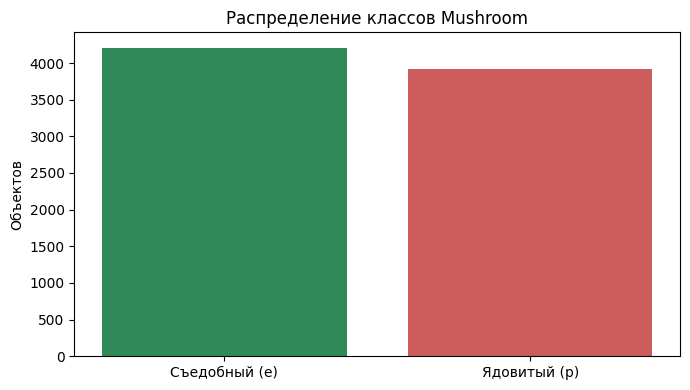

In [4]:
feature_summary = pd.DataFrame({
    "Тип": features.dtypes.astype(str),
    "Категорий без пропусков": features.nunique(),
    "Пропусков": features.isna().sum(),
})
display(feature_summary)

class_counts = labels.value_counts().reindex(["e", "p"])
distribution = pd.DataFrame({
    "Класс": ["Съедобный (e)", "Ядовитый (p)"],
    "Объектов": class_counts.to_numpy(),
    "Доля, %": (class_counts.to_numpy() / len(raw) * 100).round(2),
})
display(distribution)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(distribution["Класс"], distribution["Объектов"], color=["seagreen", "indianred"])
ax.set(ylabel="Объектов", title="Распределение классов Mushroom")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "class_distribution.png", dpi=150)
plt.show()


## 2. Подготовка данных
Пропуски заменяем отдельной категорией `missing`. 
Метки: **0 — съедобный, 1 — ядовитый**.


In [5]:
split_seed = 42
train_fraction = 0.8
y = labels.map({"e": 0, "p": 1}).to_numpy(dtype=np.int64)

X_train, X_test, y_train, y_test = train_test_split(
    features, y,
    train_size=train_fraction,
    random_state=split_seed,
    stratify=y,
)

X_train = pd.get_dummies(X_train.fillna("missing"), dtype=np.float64)
X_test = pd.get_dummies(X_test.fillna("missing"), dtype=np.float64)
# Тест должен иметь те же столбцы, что и обучение, в том же порядке.
X_test = X_test.reindex(columns=X_train.columns, fill_value=0.0)

X_train = X_train.to_numpy()
X_test = X_test.to_numpy()


In [6]:
print("Обучение: признаки", X_train.shape, "; метки", y_train.shape)
print("Тест: признаки", X_test.shape, "; метки", y_test.shape)
print("Классы в обучении [съедобный, ядовитый]:", np.bincount(y_train))
print("Классы в тесте [съедобный, ядовитый]:", np.bincount(y_test))


Обучение: признаки (6499, 117) ; метки (6499,)
Тест: признаки (1625, 117) ; метки (1625,)
Классы в обучении [съедобный, ядовитый]: [3366 3133]
Классы в тесте [съедобный, ядовитый]: [842 783]


## 3. Собираем MLP из готовых слоёв

Передаём слои по одному в `NeuralNetwork(...)`: они выполняются в указанном порядке.
Для MLP используем `Linear`, `Sigmoid` и финальный `Softmax`.
Все размеры и параметры обучения задаём здесь, снаружи класса сети.
После сборки вызов `model(X)` выполняет прямой проход.


In [7]:
config = {
    "seed": 42,
    "split_seed": split_seed,
    "train_fraction": train_fraction,
    "hidden_sizes": [32, 16],
    "epochs": 500,
    "learning_rate": 0.6,
}
rng = np.random.default_rng(config["seed"])
model = NeuralNetwork(
    Linear(X_train.shape[1], 32, rng),
    Sigmoid(),
    Linear(32, 16, rng),
    Sigmoid(),
    Linear(16, 2, rng),
    Softmax(),
    learning_rate=config["learning_rate"],
    epochs=config["epochs"],
)


## 4. Обучение


In [8]:
start = perf_counter()
model.fit(X_train, y_train, verbose=True)
train_seconds = perf_counter() - start

print(f"Время обучения: {train_seconds:.2f} с")
print(f"Первая loss: {model.loss_history[0]:.6f}")
print(f"Loss последней эпохи: {model.loss_history[-1]:.6f}")


Epoch 1/500, loss=0.706579
Epoch 51/500, loss=0.280971
Epoch 101/500, loss=0.084418
Epoch 151/500, loss=0.044361
Epoch 201/500, loss=0.027423
Epoch 251/500, loss=0.019455
Epoch 301/500, loss=0.014678
Epoch 351/500, loss=0.011339
Epoch 401/500, loss=0.008921
Epoch 451/500, loss=0.007184
Epoch 500/500, loss=0.005942
Время обучения: 1.64 с
Первая loss: 0.706579
Loss последней эпохи: 0.005942


## 5. Метрики на тестовой выборке


In [9]:
probabilities = model(X_test)
y_pred = probabilities.argmax(axis=1)
y_prob = probabilities[:, 1]
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred, pos_label=1, zero_division=0)),
    "recall": float(recall_score(y_test, y_pred, pos_label=1, zero_division=0)),
    "f1": float(f1_score(y_test, y_pred, pos_label=1, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "test_loss": float(model.loss(probabilities, y_test)),
    "train_loss_last_epoch": float(model.loss_history[-1]),
    "train_samples": len(y_train),
    "test_samples": len(y_test),
    "input_features": X_train.shape[1],
    "epochs_completed": len(model.loss_history),
    "train_seconds": train_seconds,
}

metric_rows = [
    ["Accuracy", metrics["accuracy"]],
    ["Precision (ядовитый)", metrics["precision"]],
    ["Recall (ядовитый)", metrics["recall"]],
    ["F1 (ядовитый)", metrics["f1"]],
    ["ROC-AUC", metrics["roc_auc"]],
    ["Тестовая loss", metrics["test_loss"]],
]
metric_table = pd.DataFrame(metric_rows, columns=["Метрика", "Значение"])
display(metric_table.round(6))


,Метрика,Значение
0,Accuracy,0.998154
1,Precision (ядовитый),1.000000
2,Recall (ядовитый),0.996169
3,F1 (ядовитый),0.998081
4,ROC-AUC,0.999995
5,Тестовая loss,0.008205


### Функция потерь



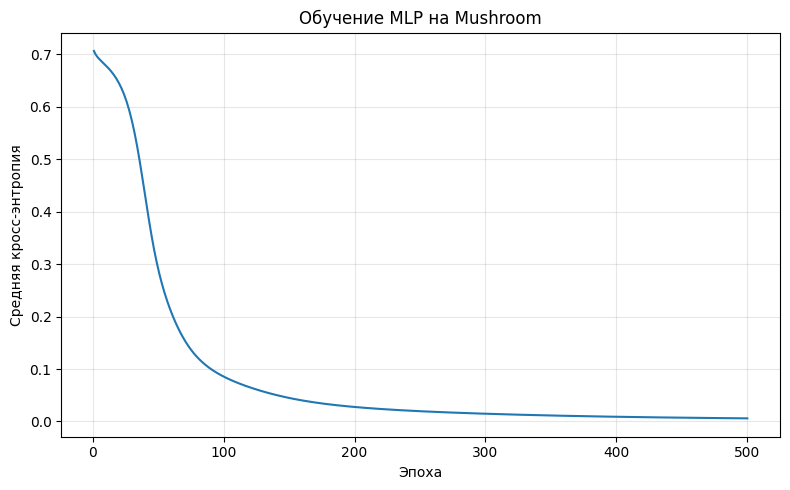

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history)
ax.set(xlabel="Эпоха", ylabel="Средняя кросс-энтропия", title="Обучение MLP на Mushroom")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "loss.png", dpi=150)
plt.show()


### ROC-кривая

Готовый метод `RocCurveDisplay.from_predictions` строит ROC-кривую и указывает AUC в легенде.
Передаём ему настоящие метки и вероятности ядовитого класса.


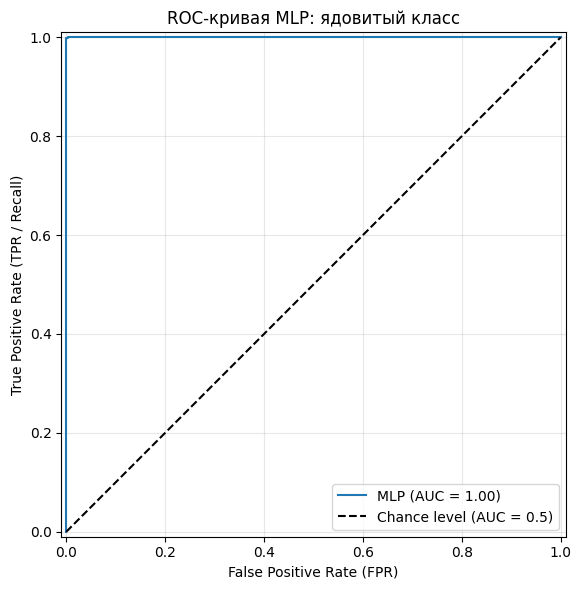

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    pos_label=1,
    name="MLP",
    plot_chance_level=True,
    ax=ax,
)
ax.set(
    xlabel="False Positive Rate (FPR)",
    ylabel="True Positive Rate (TPR / Recall)",
    title="ROC-кривая MLP: ядовитый класс",
)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "roc.png", dpi=150)
plt.show()


### Матрица ошибок


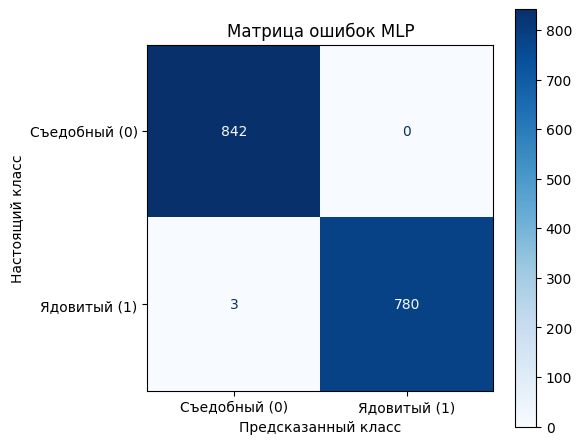

Правильных ответов: 1622 из 1625
Ядовитых названо съедобными: 3
Съедобных названо ядовитыми: 0


In [12]:
class_names = ["Съедобный (0)", "Ядовитый (1)"]
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=class_names,
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set(
    xlabel="Предсказанный класс",
    ylabel="Настоящий класс",
    title="Матрица ошибок MLP",
)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "confusion_matrix.png", dpi=150)
plt.show()
print(f"Правильных ответов: {matrix.trace()} из {len(y_test)}")
print(f"Ядовитых названо съедобными: {matrix[1, 0]}")
print(f"Съедобных названо ядовитыми: {matrix[0, 1]}")
